In [49]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from autoaugment.augment import AugmentTS
from data_provider.data_factory import Dataset_ETT_minute, Dataset_Custom


In [41]:
# choose dataset!
dataset = 'ECL' #ili, Exchange, traffic etc

# choose magnitude
mag = 0.85  #pick a magnitude in [0,1]

In [54]:
root_path = {}
data_path = {}
seasonality = {}

root_path['ili'] = './dataset/illness/'
data_path['ili'] = 'national_illness.csv'
seasonality['ili'] = 52

root_path['ETTm2'] = './dataset/ETT-small/'
data_path['ETTm2'] = 'ETTm2.csv'
seasonality['ETTm2'] = 96

root_path['ECL'] = './dataset/electricity/'
data_path['ECL'] = 'electricity.csv'
seasonality['ECL'] = 96

root_path['Exchange'] = './dataset/exchange_rate/'
data_path['Exchange'] = 'exchange_rate.csv'
seasonality['Exchange'] = 30

root_path['traffic'] = './dataset/traffic/'
data_path['traffic'] = 'traffic.csv'
seasonality['traffic'] = 24

root_path['weather'] = './dataset/weather/'
data_path['weather'] = 'weather.csv'
seasonality['weather'] = 144

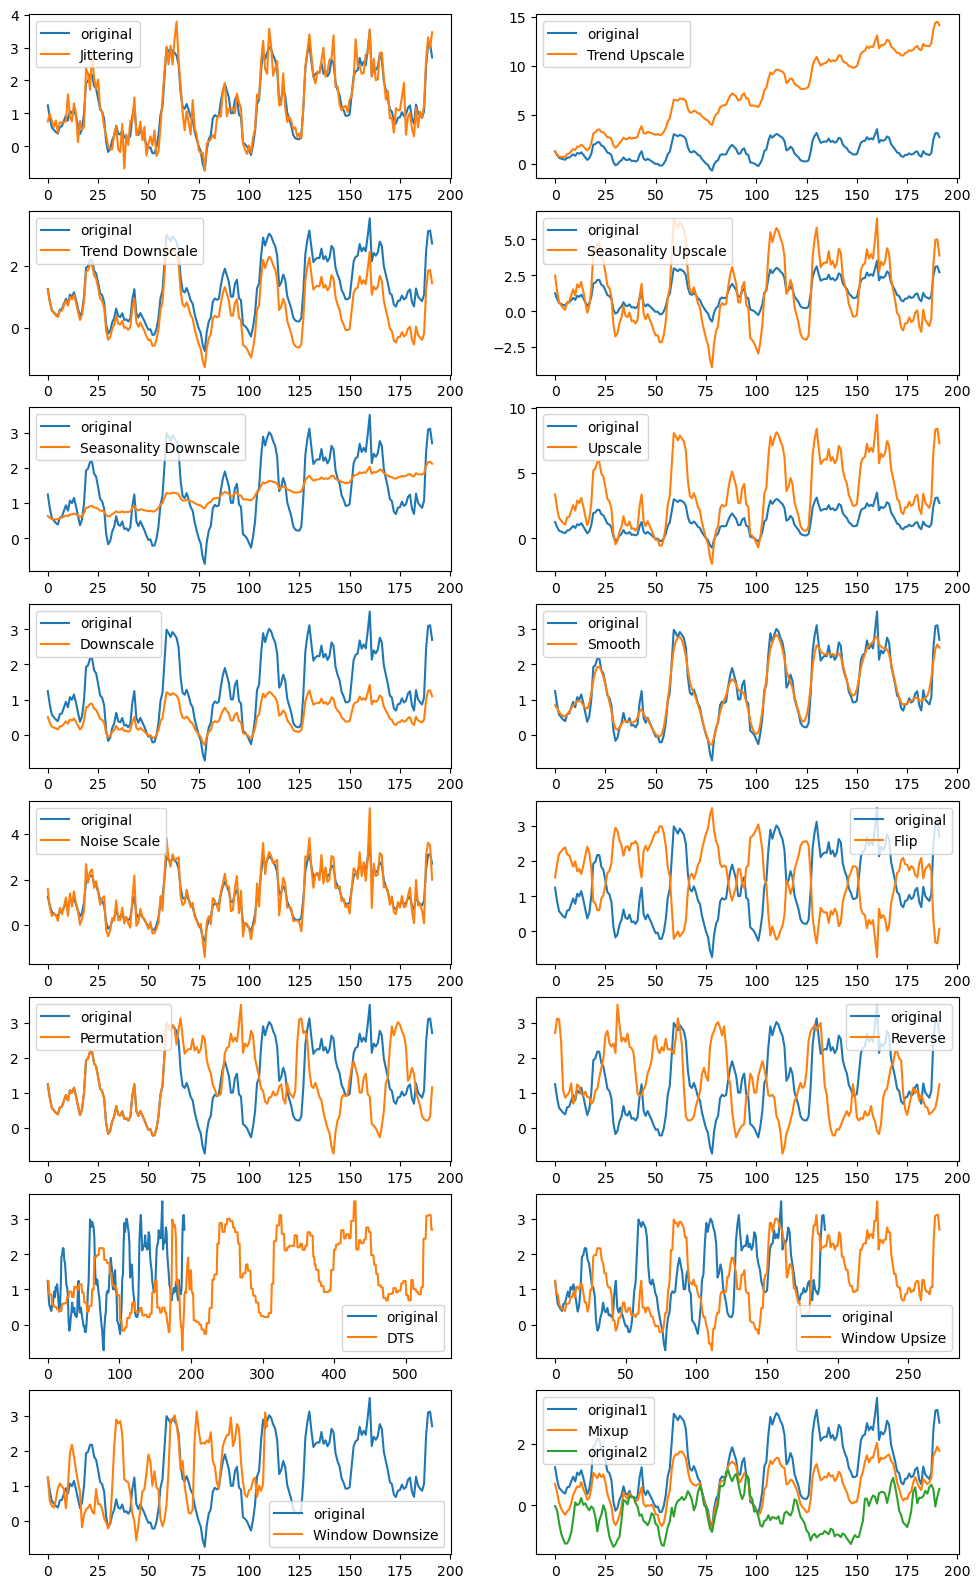

In [59]:
# get the data
length = 192
if dataset == 'ili':
    length = 60

data = Dataset_Custom(root_path =root_path[dataset],
                      data_path = data_path[dataset],
                      flag = 'train',
                      features = 'S')
data = data.data_x.flatten()
mini_batch = []
#length = 200

for i in range(2):
    rand_i = np.random.randint(0,len(data)-length)
    mini_batch.append(data[rand_i:rand_i+length])   
data = np.stack(mini_batch)
data = torch.tensor(data).float()



fs = 10
n_tr = len(aug.transformations)

f, ax = plt.subplots( n_tr//2, 2, figsize=(12, 20) )

for i in range(n_tr//2):
    key1 = list(aug.transformations.keys())[i*2]
    data_aug1 = aug.apply_op(data,key1,mag)
    ax[i,0].plot(data[0,:])
    ax[i,0].plot(data_aug1[0,:])
    ax[i,0].legend(['original',key1],fontsize=fs)
    
    key2 = list(aug.transformations.keys())[i*2+1]
    
    
    data_aug2 = aug.apply_op(data,key2,mag)
    ax[i,1].plot(data[0,:])
    ax[i,1].plot(data_aug2[0,:])
    if key2=="Mixup":
        ax[i,1].plot(data[1,:])
        ax[i,1].legend(['original1',key2,'original2'],fontsize=fs)
    else:            
        ax[i,1].legend(['original',key2],fontsize=fs)
# to pdf
plt.savefig('augmentations.pdf', bbox_inches='tight')

    
plt.show()

In [52]:
# augmentations
aug = AugmentTS(seasonality = seasonality[dataset])
aug.transformations

{'Jittering': {'range': (0.0, 0.1),
  'func': <function autoaugment.augment.jittering(data, mag, rng=None)>},
 'Trend Upscale': {'range': (1.0, 10.0),
  'func': <function autoaugment.augment.trend_scale(data, mag, seasonality=12, stl_decomp=None)>},
 'Trend Downscale': {'range': (0.0, 1.0),
  'func': <function autoaugment.augment.trend_scale(data, mag, seasonality=12, stl_decomp=None)>},
 'Seasonality Upscale': {'range': (1.0, 3.0),
  'func': <function autoaugment.augment.seasonality_scale(data, mag, seasonality=12, stl_decomp=None)>},
 'Seasonality Downscale': {'range': (0.0, 1.0),
  'func': <function autoaugment.augment.seasonality_scale(data, mag, seasonality=12, stl_decomp=None)>},
 'Upscale': {'range': (1.0, 3),
  'func': <function autoaugment.augment.scale(data, mag)>},
 'Downscale': {'range': (0.3, 1.0),
  'func': <function autoaugment.augment.scale(data, mag)>},
 'Smooth': {'range': (0.0, 11.0),
  'func': <function autoaugment.augment.low_pass(data, mag)>},
 'Noise Scale': {'ra

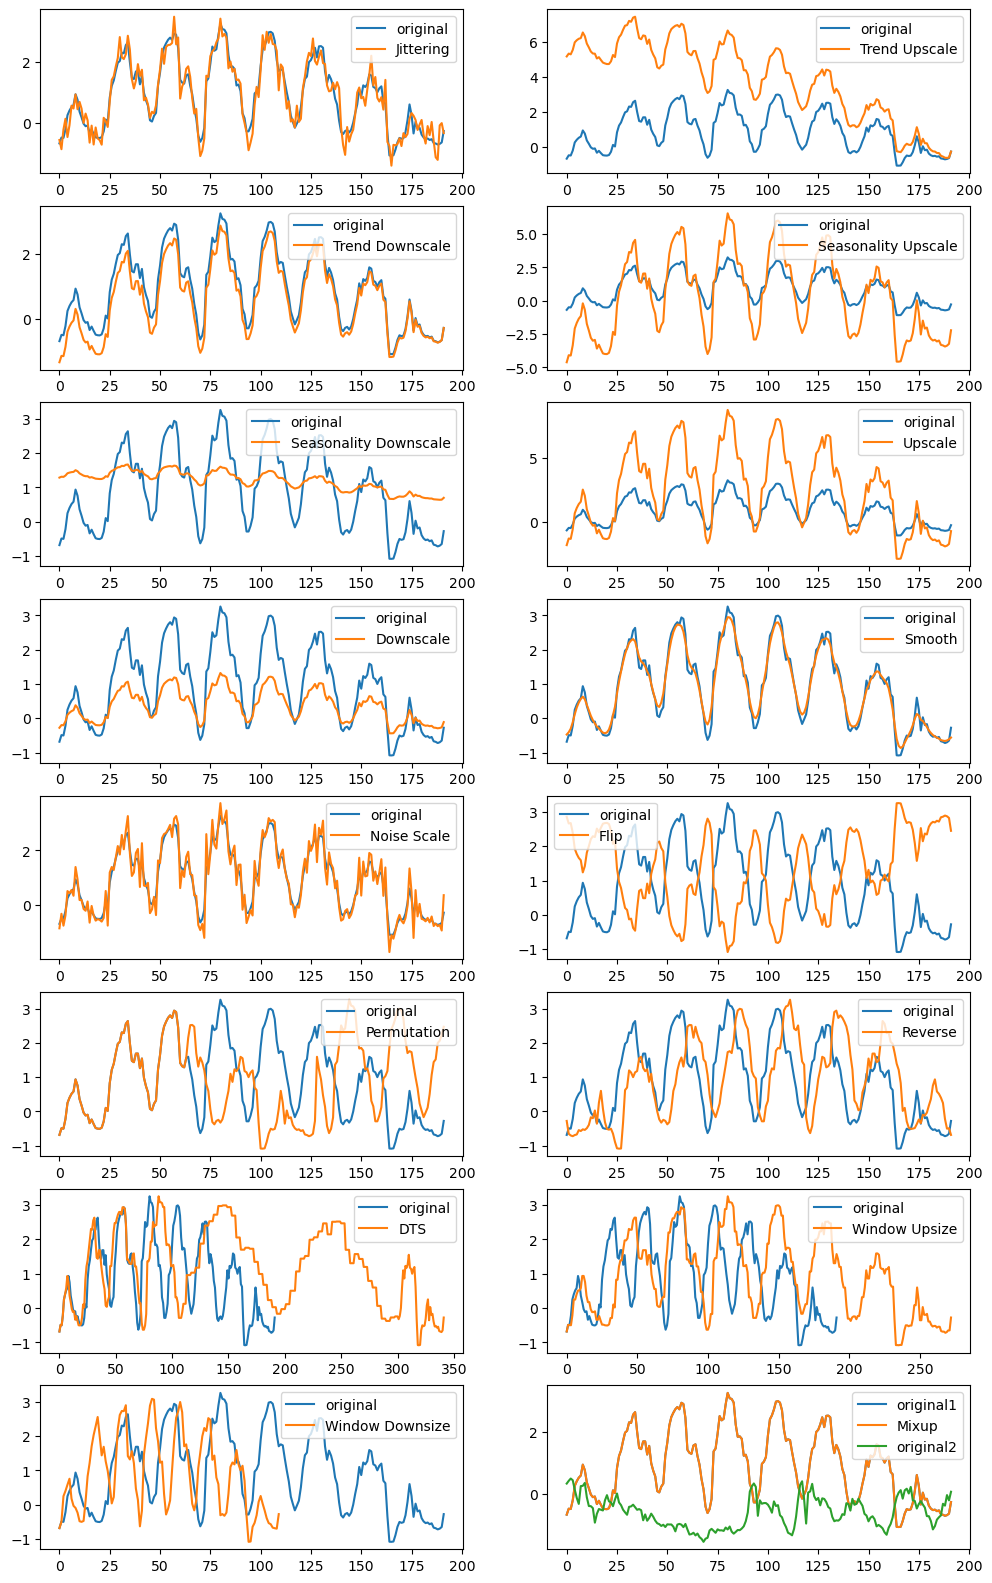

In [53]:
fs = 10
n_tr = len(aug.transformations)

f, ax = plt.subplots( n_tr//2, 2, figsize=(12, 20) )

for i in range(n_tr//2):
    key1 = list(aug.transformations.keys())[i*2]
    data_aug1 = aug.apply_op(data,key1,mag)
    ax[i,0].plot(data[0,:])
    ax[i,0].plot(data_aug1[0,:])
    ax[i,0].legend(['original',key1],fontsize=fs)
    
    key2 = list(aug.transformations.keys())[i*2+1]
    
    
    data_aug2 = aug.apply_op(data,key2,mag)
    ax[i,1].plot(data[0,:])
    ax[i,1].plot(data_aug2[0,:])
    if key2=="Mixup":
        ax[i,1].plot(data[1,:])
        ax[i,1].legend(['original1',key2,'original2'],fontsize=fs)
    else:            
        ax[i,1].legend(['original',key2],fontsize=fs)
# to pdf
plt.savefig('augmentations.pdf')

    
plt.show()

In [15]:
list(aug.transformations.keys())

['Jittering',
 'Trend Upscale',
 'Trend Downscale',
 'Seasonality Upscale',
 'Seasonality Downscale',
 'Upscale',
 'Downscale',
 'Smooth',
 'Noise Scale',
 'Flip',
 'Permutation',
 'Reverse',
 'DTS',
 'Window Upsize',
 'Window Downsize',
 'Mixup',
 'Identity']